introduction and data overview

In [8]:
import pandas as pd

df = pd.read_csv("E-commerce Sales.csv")

print(df.shape)
print(df.info())


(5000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   str    
 4   region            5000 non-null   str    
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   str    
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), str(4)
memory usage: 468.9 KB
None


In [9]:
print(df.head())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33         Wallet              4              4.9   

   revenue  
0  1883.20  
1   304.10  
2   644.35  
3  2569.90  
4   468.56  
order_id            0
order_date      


Initial Data Inspection

The dataset contains 5,000 records and 12 columns.

- No missing values were detected.
- No fully duplicated rows were found.
- The dataset includes order, customer, product, regional, and sales information.
- The `order_date` column is currently stored as a string and requires date conversion.


Data Preparation

In [10]:
df["order_date"] = pd.to_datetime(
    df["order_date"],
    format="%m/%d/%Y"
)

print(df["order_date"].dtype)
print("First date:", df["order_date"].min())
print("Last date:", df["order_date"].max())

datetime64[us]
First date: 2022-01-01 00:00:00
Last date: 2035-09-09 00:00:00


In [11]:
print("Missing dates:", df["order_date"].isna().sum())
print("Data types:")
print(df.dtypes)

Missing dates: 0
Data types:
order_id                     int64
order_date          datetime64[us]
customer_id                  int64
product_category               str
region                         str
quantity                     int64
unit_price                 float64
discount                   float64
payment_method                 str
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object


Product Category Analysis

In [12]:
category_analysis = df.groupby("product_category").agg(
    orders=("order_id", "count"),
    total_revenue=("revenue", "sum"),
    avg_revenue=("revenue", "mean")
).round(2)

category_analysis = category_analysis.sort_values(
    "total_revenue", ascending=False
)

category_analysis

,orders,total_revenue,avg_revenue
product_category,,,
Electronics,1777,1829899.22,1029.77
Clothing,1531,1531931.72,1000.61
Home,969,982083.92,1013.50
Beauty,723,765860.88,1059.28


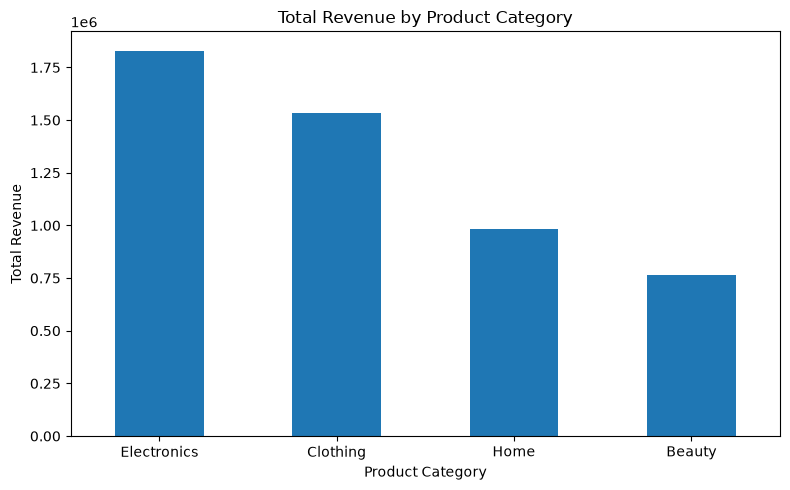

In [13]:
import matplotlib.pyplot as plt

category_analysis["total_revenue"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Product Category",
    ylabel="Total Revenue",
    xlabel="Product Category"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Key Findings

- Electronics generated the highest total revenue (1,829,899.22) and recorded the highest number of orders (1,777).
- Beauty achieved the highest average revenue per order (1,059.28), despite having the lowest order volume.
- No single category leads across all performance indicators.

**Business Insight:**

Electronics is the main revenue contributor, while Beauty generates more revenue per order on average. These findings suggest different opportunities for category-level business strategies.


Regional Analysis

In [14]:
region_analysis = df.groupby("region").agg(
    orders=("order_id", "count"),
    total_revenue=("revenue", "sum"),
    avg_revenue=("revenue", "mean")
).round(2)

region_analysis = region_analysis.sort_values(
    "total_revenue", ascending=False
)

region_analysis

,orders,total_revenue,avg_revenue
region,,,
West,1289,1345582.16,1043.90
North,1276,1281508.45,1004.32
South,1208,1246640.90,1031.99
East,1227,1236044.23,1007.37


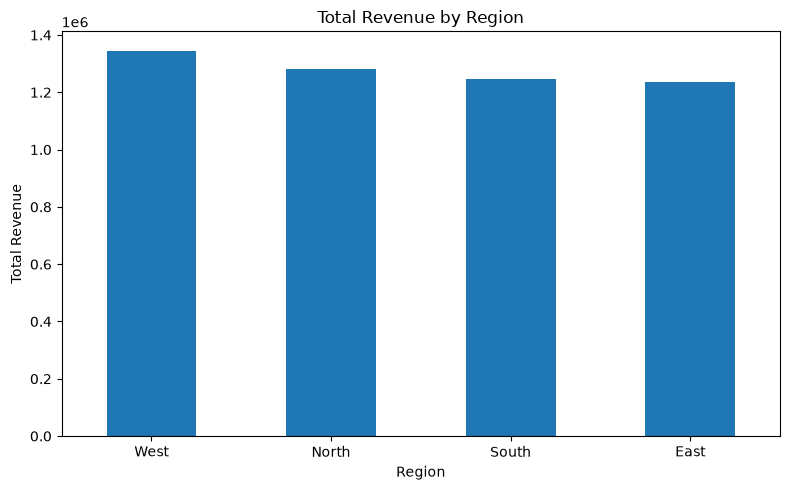

In [15]:
region_analysis["total_revenue"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Region",
    ylabel="Total Revenue",
    xlabel="Region"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Key Findings

- West generated the highest total revenue (1,345,582.16) and recorded the highest number of orders (1,289).
- West also achieved the highest average revenue per order (1,043.90).
- South ranked second in average revenue per order (1,031.99), despite having fewer orders than North and East.

**Business Insight:**

West is the strongest-performing region across the three measured indicators. However, these results describe observed performance and do not establish the causes behind regional differences.


Customer Analysis

In [16]:
customer_analysis = df.groupby("customer_id").agg(
    orders=("order_id", "count"),
    total_revenue=("revenue", "sum")
)

customer_analysis = customer_analysis.sort_values(
    "total_revenue", ascending=False
)

customer_analysis.head(10)

,orders,total_revenue
customer_id,,
1663,14,17680.69
1955,10,16265.15
1675,11,15036.46
1276,11,15023.71
1647,11,14894.97
1804,10,14330.98
1193,7,14151.65
1836,9,14110.78
1957,12,13956.95


In [17]:
print("Unique customers:", df["customer_id"].nunique())

print("Average orders per customer:",
      customer_analysis["orders"].mean().round(2))

print("Maximum orders by one customer:",
      customer_analysis["orders"].max())

print("One-time customers:",
      (customer_analysis["orders"] == 1).sum())

top_10_share = (
    customer_analysis.head(10)["total_revenue"].sum()
    / df["revenue"].sum()
) * 100

print("Top 10 customers revenue share:",
      round(top_10_share, 2), "%")

Unique customers: 989
Average orders per customer: 5.06
Maximum orders by one customer: 14
One-time customers: 39
Top 10 customers revenue share: 2.91 %


Key Findings

- The dataset contains 989 unique customers and 5,000 orders.
- Each customer placed an average of 5.06 orders.
- The highest number of orders placed by a single customer was 14.
- Only 39 customers made a single purchase.
- The top 10 customers contributed approximately 2.91% of total revenue.

**Business Insight:**

Revenue is not heavily concentrated among the top 10 customers. This suggests that the business generates revenue from a relatively broad customer base rather than relying primarily on a small group of high-value customers.



# 6. Key Findings & Data Limitations

## Overall Key Findings

1. Electronics generated the highest total revenue, while Beauty achieved the highest average revenue per order.
2. West was the strongest-performing region across order volume, total revenue, and average revenue per order.
3. The top 10 customers contributed only 2.91% of total revenue, indicating low revenue concentration among the highest-value customers.

## Data Limitations

- The dataset covers an unusually long period, from 2022 to 2035.
- There is exactly one order recorded per calendar day across the available date range, which may limit the realism of time-based analysis.
- The dataset does not document the formula used to calculate revenue.
- The method used to generate customer ratings is not documented.
- Revenue does not represent profit because product costs and operating expenses are unavailable.

## Conclusion

The analysis identified differences in product category performance, regional revenue, and customer purchasing behavior. However, the findings should be interpreted within the limitations of the available dataset.
